# Dichotic (left + right together): overt and masked onsets, intensity-level control

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Both dichotic halves pooled (the `dichotic` epoch: ignored speaker on the left and on the right),
to compare with `dichotic_left_overt_masked_onsets.ipynb` and `dichotic_right_overt_masked_onsets.ipynb`.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Overt/masked predictors** (`predictors/brodbeck2020_predictors.py`): split element-wise at full
frequency resolution and only then binned into 8 bands, with each speaker at its level in the
mixture that was played (the speakers' own files are 4x louder), as Brodbeck et al. 2020 defined
it. `SPLIT_RECIPE` in `parameters.py` picks the spectrogram: `'b20'`, the paper's (256 bands,
20-5,000 Hz, exponent 0.6), or `'log'`, the one the other notebooks use (128 bands, 80-8,000 Hz,
log(x + 1)). The split is tested against the same onsets unsplit (`FULL_INMIX`).

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('dichotic_overt_masked_onsets')

ROI from the clean notebook (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
All 12 results this notebook reads are on the cluster.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-dichotic_right-9860651.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-19 11:59:33 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-19 12:00:20 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== dichotic_ri

## Dichotic (left + right) (overt onsets)

In [5]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('dichotic_overt_masked_onsets')

ROI imported from roi.txt (~/projects/def-ibruce/iggy/dataset/cocktail/bids/derivatives/results/roi.txt), determined by the clean-speech notebook from its onset and envelope test - baseline topomaps (conjunction: significant for every predictor).
Used for every ROI test, STRF, TRF waveform and peak below.

ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2


Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


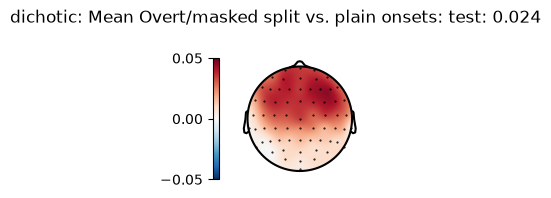

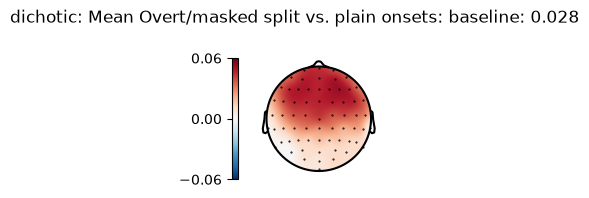

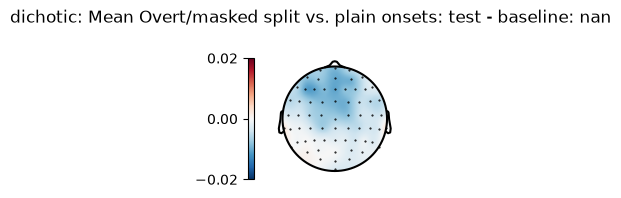

In [6]:
# Overt/masked split vs. plain onsets (dichotic)
# overt/masked = the split of each speaker's onsets into the part still visible in the mixture and
# the part the other speaker covers, with the speaker at its level in the mixture.
# Brodbeck et al. 2020 ran this comparison too: splitting onsets into overt/masked significantly improved the model overall, t = 6.81, p < .001.

# FULL_INMIX  = Eatt + Oatt + Eign + Oign + Emix + Omix   (Oatt, Oign at their level in the mixture)
# FULL_MASKED = Eatt + Oatt_overt + Oatt_masked + Eign + Oign_overt + Oign_masked + Emix + Omix
#
# Comparison: FULL_MASKED > FULL_INMIX
#   (does splitting Oatt/Oign into overt + masked improve the fit? overt + masked == Oatt/Oign,
#   so the two models carry the same onsets, only split or not)
#
# Full predictor names: print(FULL_MASKED) and print(FULL_INMIX); <recipe> is SPLIT_RECIPE
# (parameters.py), e.g. gammatone-<recipe>-on-overt-8 for the attended overt onsets.

data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_INMIX, 'dichotic')
show_topomap_trio(data, diff, result, 'Overt/masked split vs. plain onsets', 'dichotic', None)

In [7]:
display(result)
print(f"Overt/masked split vs. plain onsets (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt/masked split vs. plain onsets (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Overt/masked split vs. plain onsets (dichotic): TFCE t_max = -1.17, p = 1.000
Overt/masked split vs. plain onsets (dichotic): ROI model comparison t(12) = -2.036, p = 0.9678


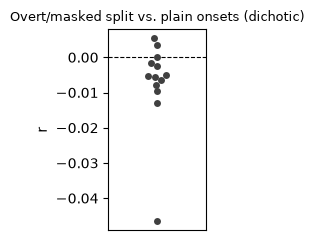

In [8]:
p = show_subject_swarm(diff, 'Overt/masked split vs. plain onsets', 'dichotic')

In [9]:
# Loaded once here, reused by every STRF/peak/waveform/attention-
# effect/masking-comparison cell in both this subsection and "masked
# onset" below - same reasoning as data_full above, for FULL_MASKED.
data_masked = load_trfs_saved(FULL_MASKED, 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

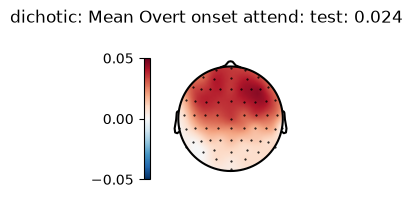

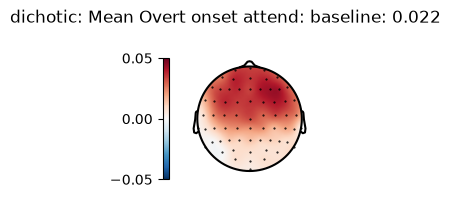

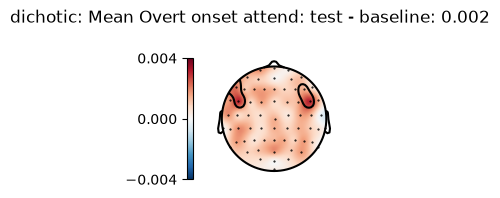

In [10]:
# Overt onset attend unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt onsets unique contribution, t = 3.34, p = .027.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(ATTEND), 'dichotic')
show_topomap_trio(data, diff, result, 'Overt onset attend', 'dichotic', overt_onset(ATTEND))

In [11]:
display(result)
print(f"Overt onset attend (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset attend (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .034>

Overt onset attend (dichotic): TFCE t_max = 3.08, p = 0.034
Overt onset attend (dichotic): ROI unique contribution t(12) = 2.707, p = 0.0095


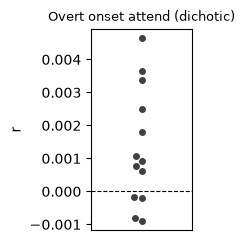

In [12]:
p = show_subject_swarm(diff, 'Overt onset attend', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


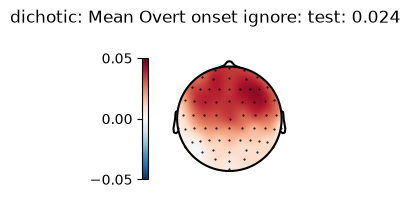

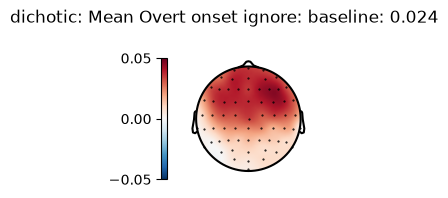

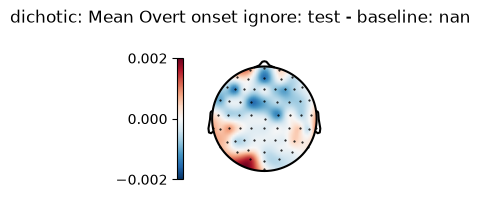

In [13]:
# Overt onset ignore unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt onsets unique contribution, t = 3.82, p = .016.
data, diff, result = compute_unique_contribution(FULL_MASKED, overt_onset(IGNORE), 'dichotic')
show_topomap_trio(data, diff, result, 'Overt onset ignore', 'dichotic', overt_onset(IGNORE))

In [14]:
display(result)
print(f"Overt onset ignore (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt onset ignore (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .996>

Overt onset ignore (dichotic): TFCE t_max = 0.12, p = 0.996
Overt onset ignore (dichotic): ROI unique contribution t(12) = -2.910, p = 0.9935


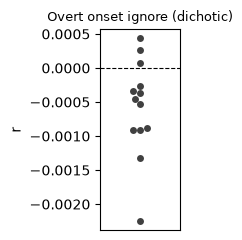

In [15]:
p = show_subject_swarm(diff, 'Overt onset ignore', 'dichotic')

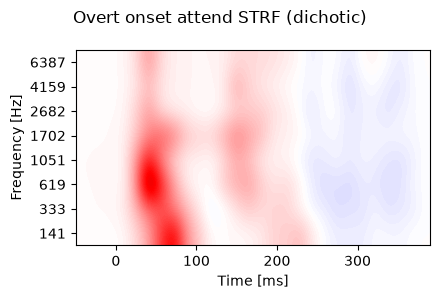

In [16]:
# Overt onset attend STRF (dichotic)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset attend STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

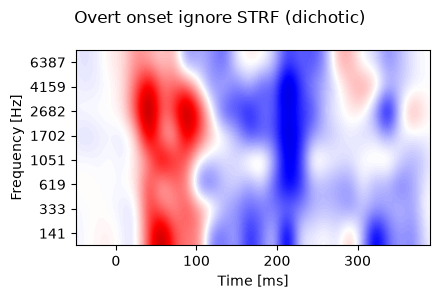

In [17]:
# Overt onset ignore STRF (dichotic)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
p = plot.Array(strf * 1e3, title='Overt onset ignore STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [18]:
# Overt onset attend peak amplitude & timing (dichotic)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset attend (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset attend (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset attend (dichotic) positive peak: 51 ms, amp 0.004473
Overt onset attend (dichotic) negative peak: 245 ms, amp -0.0004719


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (all) at 250 ms is on the edge of the search window (0.02, 0.25)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


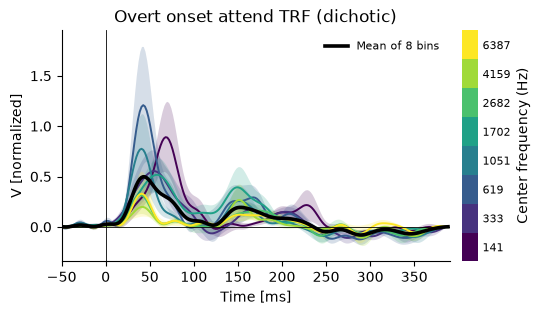

In [19]:
# Overt onset attend TRF per frequency bin (dichotic)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attend TRF (dichotic)')

In [20]:
# Overt onset ignore peak amplitude & timing (dichotic)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Overt onset ignore (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Overt onset ignore (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Overt onset ignore (dichotic) positive peak: 49 ms, amp 0.000928
Overt onset ignore (dichotic) negative peak: 219 ms, amp -0.0009423


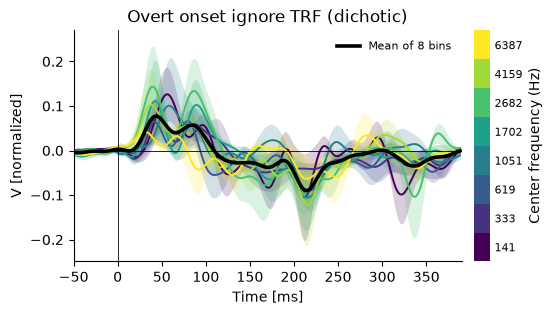

In [21]:
# Overt onset ignore TRF per frequency bin (dichotic)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset ignore TRF (dichotic)')

In [22]:
# Overt onset peak comparison across attend and ignore (dichotic)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_overt_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_overt_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (attend) at 250 ms is on the edge of the search window (0.02, 0.25)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


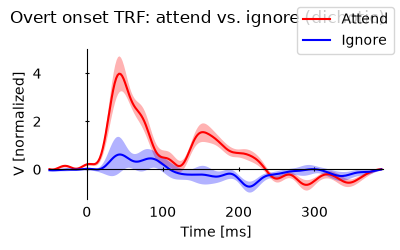

In [23]:
# The overt onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt onset TRF: attend vs. ignore (dichotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [24]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend              60     0.0009051
02        attend              52      0.004667
03        attend              46       0.00035
04        attend              46      0.002311
05        attend              39       0.01467
06        attend              54      0.002057
07        attend              56      0.003226
08        attend              45      0.009392
09        attend              66      0.005075
10        attend              48      0.003223
11        attend              41      0.003283
12        attend              39       0.00349
13        attend              66      0.005499
01        ignore              68     0.0008316
02        ignore              25     0.0002226
03        ignore              46     0.0004102
04        ignore              68     0.0002648
05        ignore              50     0.0004661
06        ignore              37      0.002974
07        ignore              48      0.00063

In [25]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='overt onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='overt onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = 0.30 p = .772


,ignore
attend,t12 = 7.07*** p < .001


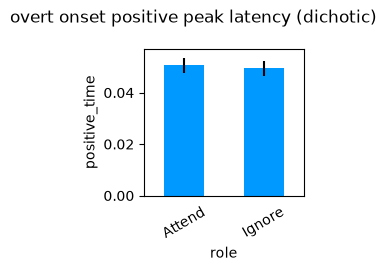

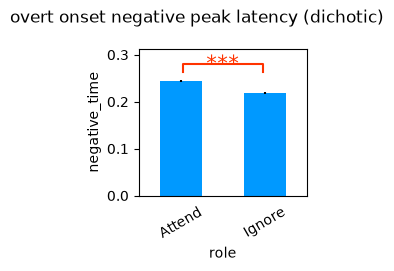

In [26]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak latency (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak latency (dichotic)')
p.set_xtick_rotation(30)

In [27]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='overt onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='overt onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 3.20** p = .008


,ignore
attend,t12 = 1.87 p = .086


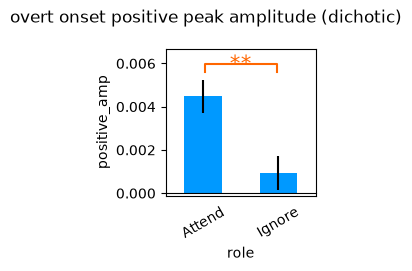

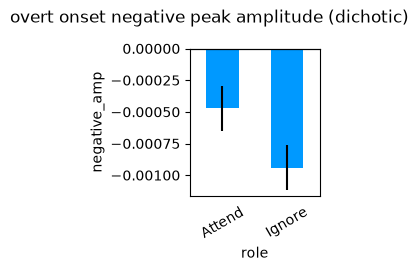

In [28]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset positive peak amplitude (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='overt onset negative peak amplitude (dichotic)')
p.set_xtick_rotation(30)

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (dichotic): bins that differ from 0 somewhere: none


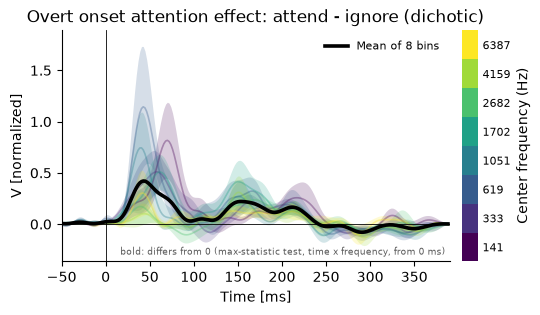

In [29]:
# Overt onset attention effect: attend - ignore (dichotic)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (dichotic)', subtract=f'bg_{SPLIT_COLUMN}_on_overt_8')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Overt onset attention effect: attend - ignore (dichotic): differs from 0 (max-statistic permutation test from 0 ms, two-tailed; ranges < 10 ms apart joined) at 48-68 ms (p = 0.001); 164-183 ms (p = 0.011); 195-218 ms (p = 0.009)


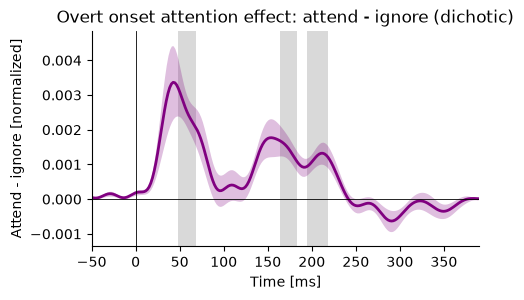

In [30]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_overt_8', f'bg_{SPLIT_COLUMN}_on_overt_8', 'Overt onset attention effect: attend - ignore (dichotic)')

## Dichotic (left + right) (masked onset)

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


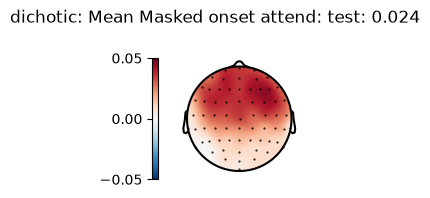

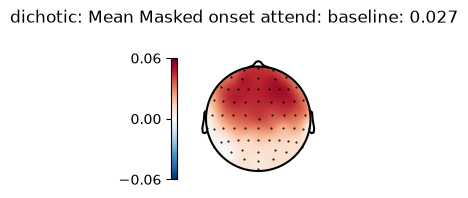

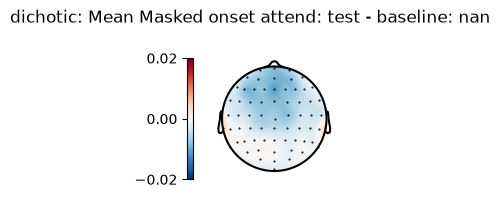

In [31]:
# Masked onset attend unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: attended masked onsets unique contribution, t = 8.42, p < .001 - the strongest of the four masking predictors.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(ATTEND), 'dichotic')
show_topomap_trio(data, diff, result, 'Masked onset attend', 'dichotic', masked_onset(ATTEND))

In [32]:
display(result)
print(f"Masked onset attend (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset attend (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Masked onset attend (dichotic): TFCE t_max = -1.15, p = 1.000
Masked onset attend (dichotic): ROI unique contribution t(12) = -1.776, p = 0.9495


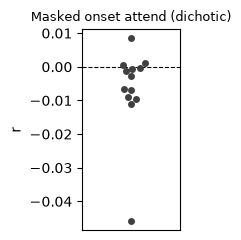

In [33]:
p = show_subject_swarm(diff, 'Masked onset attend', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


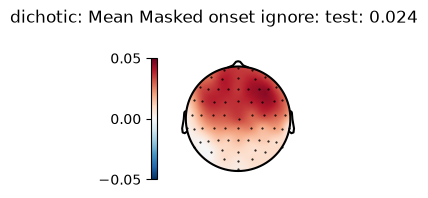

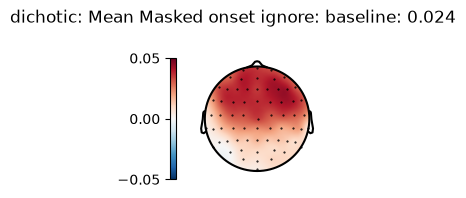

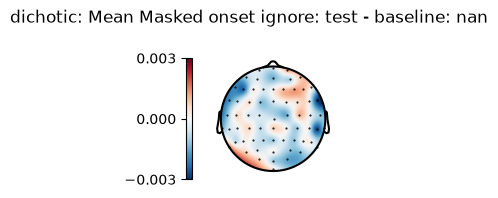

In [34]:
# Masked onset ignore unique contribution (dichotic)
# Brodbeck et al. 2020 ran this comparison too: ignored masked onsets unique contribution, t = 5.23, p < .001 - the brain recovers masked information even for the ignored speaker.
data, diff, result = compute_unique_contribution(FULL_MASKED, masked_onset(IGNORE), 'dichotic')
show_topomap_trio(data, diff, result, 'Masked onset ignore', 'dichotic', masked_onset(IGNORE))

In [35]:
display(result)
print(f"Masked onset ignore (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked onset ignore (dichotic): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .725>

Masked onset ignore (dichotic): TFCE t_max = 1.30, p = 0.725
Masked onset ignore (dichotic): ROI unique contribution t(12) = -0.931, p = 0.8148


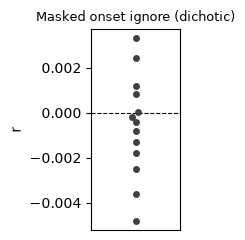

In [36]:
p = show_subject_swarm(diff, 'Masked onset ignore', 'dichotic')

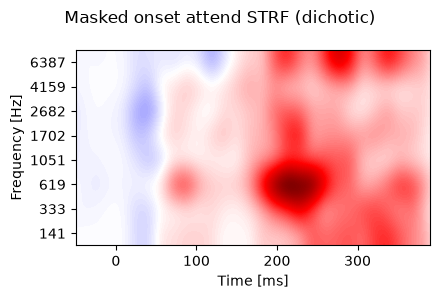

In [37]:
# Masked onset attend STRF (dichotic)
strf = extract_strf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset attend STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

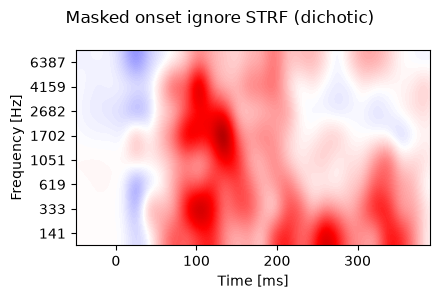

In [38]:
# Masked onset ignore STRF (dichotic)
strf = extract_strf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
p = plot.Array(strf * 1e3, title='Masked onset ignore STRF (dichotic)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [39]:
# Masked onset attend peak amplitude & timing (dichotic)
data = extract_trf(data_masked, f'{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset attend (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset attend (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset attend (dichotic) positive peak: 222 ms, amp 0.002833
Masked onset attend (dichotic) negative peak: 35 ms, amp -0.0006507


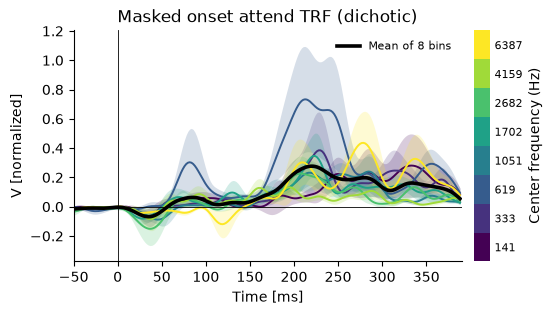

In [40]:
# Masked onset attend TRF per frequency bin (dichotic)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attend TRF (dichotic)')

In [41]:
# Masked onset ignore peak amplitude & timing (dichotic)
data = extract_trf(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8')
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Masked onset ignore (dichotic) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Masked onset ignore (dichotic) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Masked onset ignore (dichotic) positive peak: 106 ms, amp 0.001703
Masked onset ignore (dichotic) negative peak: 32 ms, amp -0.0003603


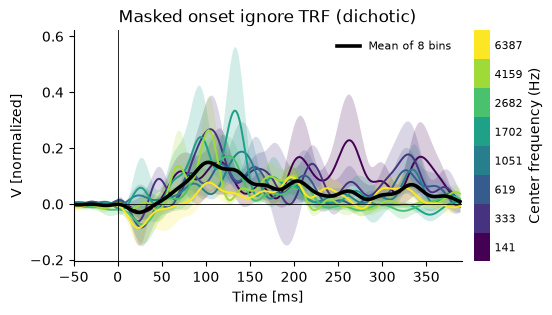

In [42]:
# Masked onset ignore TRF per frequency bin (dichotic)
p = plot_trf_bins(data_masked, f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset ignore TRF (dichotic)')

In [43]:
# Masked onset peak comparison across attend and ignore (dichotic)
dss = []
for role_name, column in (('attend', f'{SPLIT_COLUMN}_on_masked_8'), ('ignore', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

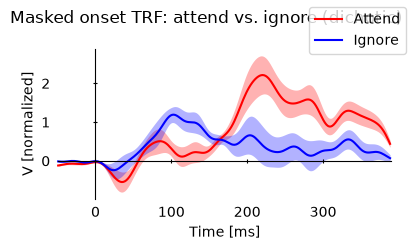

In [44]:
# The masked onset TRF waveform attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Masked onset TRF: attend vs. ignore (dichotic)', labels={'attend': 'Attend', 'ignore': 'Ignore'}, colors={'attend': 'red', 'ignore': 'blue'})

In [45]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        attend             228      0.001123
02        attend             218      0.002307
03        attend             199     0.0008957
04        attend             236     0.0004302
05        attend             222      0.004535
06        attend             230      0.001233
07        attend             244      0.001205
08        attend             207      0.009007
09        attend             244      0.004972
10        attend             216      0.003672
11        attend             218      0.002076
12        attend             222      0.003284
13        attend             199      0.002088
01        ignore             101     0.0004092
02        ignore             109      0.005108
03        ignore             127     0.0004405
04        ignore             127      0.001213
05        ignore              93       0.00163
06        ignore             127      0.002712
07        ignore             101      0.00170

In [46]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='masked onset positive peak latency: attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='masked onset negative peak latency: attend vs. ignore'))

,ignore
attend,t12 = 17.11*** p < .001


,ignore
attend,t12 = 0.66 p = .523


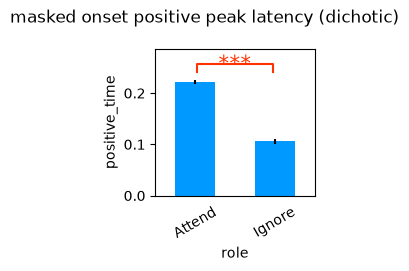

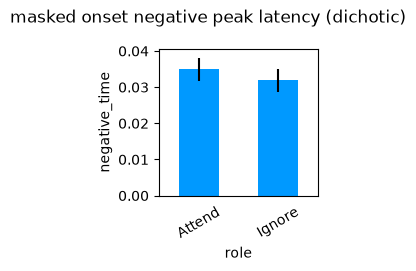

In [47]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak latency (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak latency (dichotic)')
p.set_xtick_rotation(30)

In [48]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='masked onset positive peak amplitude: attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='masked onset negative peak amplitude: attend vs. ignore'))

,ignore
attend,t12 = 1.47 p = .166


,ignore
attend,t12 = -0.82 p = .428


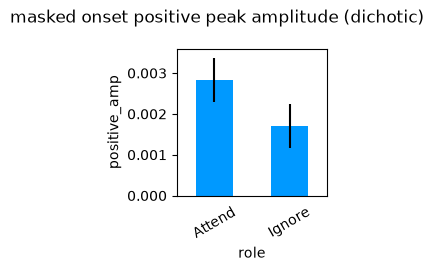

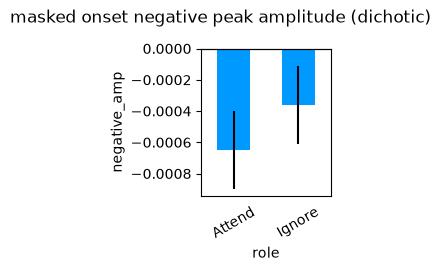

In [49]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset positive peak amplitude (dichotic)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='masked onset negative peak amplitude (dichotic)')
p.set_xtick_rotation(30)

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (dichotic): bins that differ from 0 somewhere: none


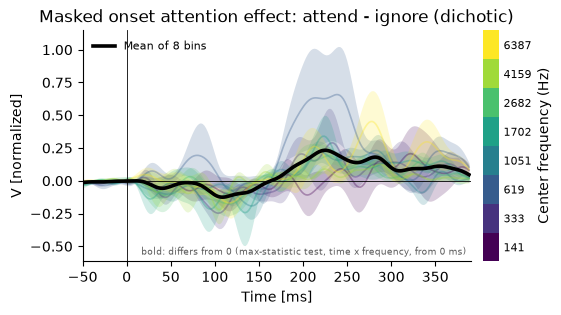

In [50]:
# Masked onset attention effect: attend - ignore (dichotic)
p = plot_trf_bins(data_masked, f'{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (dichotic)', subtract=f'bg_{SPLIT_COLUMN}_on_masked_8')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

Masked onset attention effect: attend - ignore (dichotic): no time range differs from 0 (max-statistic permutation test from 0 ms, two-tailed, smallest p = 0.094)


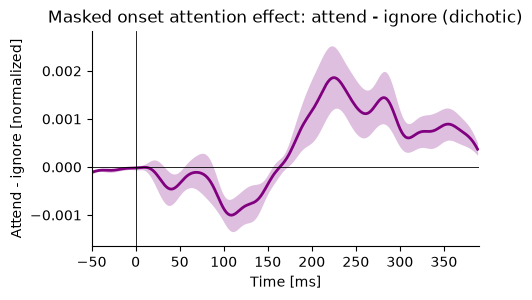

In [51]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_masked, f'{SPLIT_COLUMN}_on_masked_8', f'bg_{SPLIT_COLUMN}_on_masked_8', 'Masked onset attention effect: attend - ignore (dichotic)')

In [52]:
# Overt vs. masked peak comparison, attend (dichotic)
# Brodbeck et al. 2020 ran this comparison too: attended overt 72ms vs. attended masked 91ms (t=2.85,p=.009); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'{SPLIT_COLUMN}_on_overt_8'), ('masked', f'{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2404: UserWarning: negative anchor (overt) at 250 ms is on the edge of the search window (0.02, 0.25)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


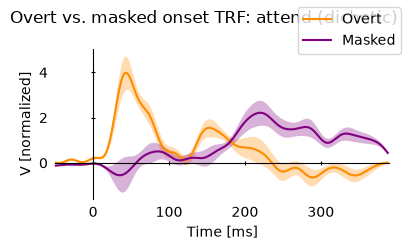

In [53]:
# Overt and masked onset TRFs of the attended speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: attend (dichotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [54]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               60     0.0009051
02        overt               52      0.004667
03        overt               46       0.00035
04        overt               46      0.002311
05        overt               39       0.01467
06        overt               54      0.002057
07        overt               56      0.003226
08        overt               45      0.009392
09        overt               66      0.005075
10        overt               48      0.003223
11        overt               41      0.003283
12        overt               39       0.00349
13        overt               66      0.005499
01        masked             228      0.001123
02        masked             218      0.002307
03        masked             199     0.0008957
04        masked             236     0.0004302
05        masked             222      0.004535
06        masked             230      0.001233
07        masked             244      0.00120

In [55]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='attend positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='attend negative peak latency: overt vs. masked'))

,masked
overt,t12 = -39.21*** p < .001


,masked
overt,t12 = 62.06*** p < .001


In [56]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='attend positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='attend negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = 2.10 p = .058


,masked
overt,t12 = 0.51 p = .620


In [57]:
# Overt vs. masked peak comparison, ignore (dichotic)
# Brodbeck et al. 2020 ran this comparison too: ignored overt 83ms vs. ignored masked 97ms (t=6.11,p<.001); combined (not stream-split) late negative peak, overt 133ms vs. masked 182ms (t=4.45,p<.001).
dss = []
for masking, column in (('overt', f'bg_{SPLIT_COLUMN}_on_overt_8'), ('masked', f'bg_{SPLIT_COLUMN}_on_masked_8')):
    ds = extract_trf(data_masked, column)
    ds[:, 'masking'] = masking
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by='masking')
data = add_anchored_peak(data, 'negative', MASKED_NEGATIVE_PEAK_WINDOW, kind='min', by='masking')

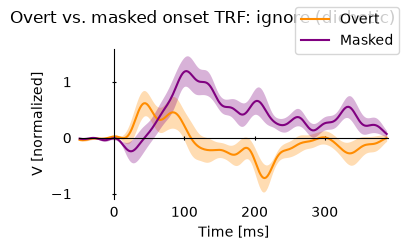

In [58]:
# Overt and masked onset TRFs of the ignored speaker, overlaid
p = plot.UTSStat('trf_sm*1e3', 'masking', data=data, match='subject', within_subject_error=True, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Overt vs. masked onset TRF: ignore (dichotic)', labels=LABELS_MASKING, colors=COLORS_MASKING)

In [59]:
print_peak_table(data, 'positive', 'masking')
print_peak_table(data, 'negative', 'masking')


positive peak
subject   masking      time (ms)           amp
01        overt               68     0.0008316
02        overt               25     0.0002226
03        overt               46     0.0004102
04        overt               68     0.0002648
05        overt               50     0.0004661
06        overt               37      0.002974
07        overt               48      0.000635
08        overt               43      0.002037
09        overt               68     0.0003471
10        overt               68      0.001844
11        overt               45       0.00187
12        overt               21     0.0001768
13        overt               56    -1.676e-05
01        masked             101     0.0004092
02        masked             109      0.005108
03        masked             127     0.0004405
04        masked             127      0.001213
05        masked              93       0.00163
06        masked             127      0.002712
07        masked             101      0.00170

In [60]:
display(test.pairwise('positive_time', 'masking', match='subject', data=data, corr=False, title='ignore positive peak latency: overt vs. masked'))
display(test.pairwise('negative_time', 'masking', match='subject', data=data, corr=False, title='ignore negative peak latency: overt vs. masked'))

,masked
overt,t12 = -8.92*** p < .001


,masked
overt,t12 = 41.42*** p < .001


In [61]:
display(test.pairwise('positive_amp', 'masking', match='subject', data=data, corr=False, title='ignore positive peak amplitude: overt vs. masked'))
display(test.pairwise('negative_amp', 'masking', match='subject', data=data, corr=False, title='ignore negative peak amplitude: overt vs. masked'))

,masked
overt,t12 = -1.59 p = .139


,masked
overt,t12 = -1.54 p = .151


In [62]:
# Stream x masking interaction on peak amplitude (dichotic)
# Brodbeck et al. 2020 ran this comparison too: stream x masking interaction, F(1,25) = 24.45, p < .001 - overt onsets show no early attention effect, masked onsets do.
dss = []
for stream_name, is_attend in (('attend', True), ('ignore', False)):
    for masking_name in ('overt', 'masked'):
        prefix = '' if is_attend else 'bg_'
        column = f'{prefix}{SPLIT_COLUMN}_on_{masking_name}_8'
        ds = extract_trf(data_masked, column)
        ds[:, 'stream'] = stream_name
        ds[:, 'masking'] = masking_name
        dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', MASKED_POSITIVE_PEAK_WINDOW, kind='max', by=('stream', 'masking'))
display(test.ANOVA('positive_amp', 'stream * masking * subject', data=data, title='stream x masking interaction (dichotic)'))

<ANOVA: positive_amp ~ stream + masking + stream x masking + subject + stream x subject + masking x subject + stream x masking x subject
  
  stream x masking interaction (dichotic)
  
                       SS   df     MS   MS(denom)   df(denom)         F      p
  ----------------------------------------------------------------------------
  stream             0.00    1   0.00        0.00          12   8.26*     .014
  masking            0.00    1   0.00        0.00          12   1.05      .326
  stream x masking   0.00    1   0.00        0.00          12   5.91*     .032
  ----------------------------------------------------------------------------
  Total              0.00   51
>

## Dichotic (left + right) (intensity-level control)

### Overt and masked onsets together

Overt and masked onsets are made from the same syllable starts, so they rise and fall together. Removed one at a time (the tests above), each can stand in for the other, and both can look useless even when the speaker's onsets matter. Here both are removed at once: if the speaker's onsets add predictive power, this joint test should show it, as the unsplit onset does (the reference tests below, the same onsets unsplit, at the speaker's level in the mixture).

- Joint test significant, one-at-a-time tests not: the information is there, but overt and masked cannot be told apart in these data.
- Joint test not significant either: the overt/masked predictors carry less than the unsplit onsets.

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


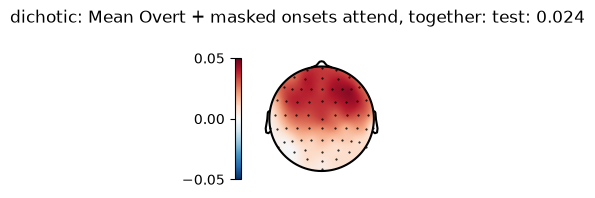

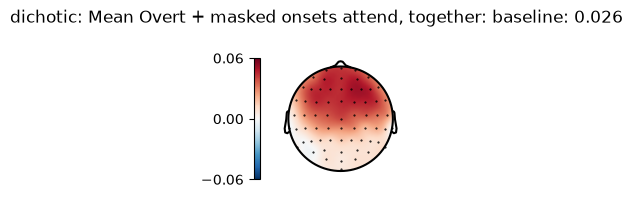

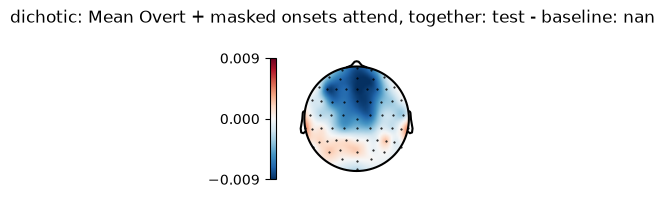

In [63]:
# Overt + masked onsets attend, together (dichotic)
# both of the attended speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_ATTEND_ONSETS, 'dichotic')
show_topomap_trio(data, diff, result, 'Overt + masked onsets attend, together', 'dichotic', None)

In [64]:
display(result)
print(f"Overt + masked onsets attend, together (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets attend, together (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Overt + masked onsets attend, together (dichotic): TFCE t_max = -0.50, p = 1.000
Overt + masked onsets attend, together (dichotic): ROI model comparison t(12) = -1.444, p = 0.9129


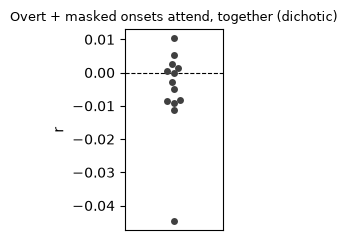

In [65]:
p = show_subject_swarm(diff, 'Overt + masked onsets attend, together', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


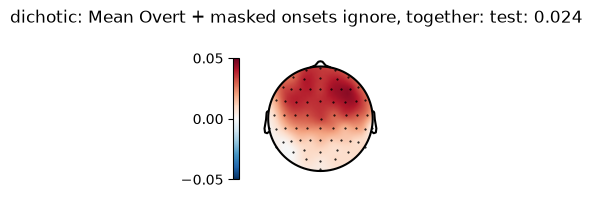

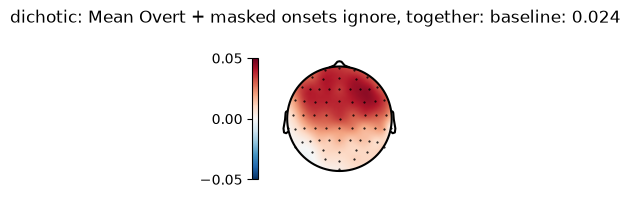

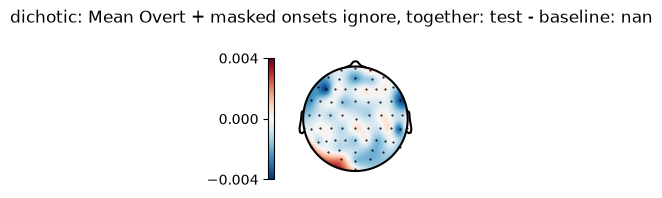

In [66]:
# Overt + masked onsets ignore, together (dichotic)
# both of the ignored speaker's onset predictors removed at once
data, diff, result = compute_direct_comparison(FULL_MASKED, FULL_MASKED_NO_IGNORE_ONSETS, 'dichotic')
show_topomap_trio(data, diff, result, 'Overt + masked onsets ignore, together', 'dichotic', None)

In [67]:
display(result)
print(f"Overt + masked onsets ignore, together (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Overt + masked onsets ignore, together (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .959>

Overt + masked onsets ignore, together (dichotic): TFCE t_max = 0.34, p = 0.959
Overt + masked onsets ignore, together (dichotic): ROI model comparison t(12) = -1.550, p = 0.9265


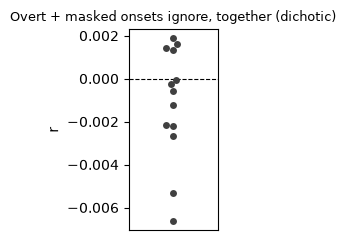

In [68]:
p = show_subject_swarm(diff, 'Overt + masked onsets ignore, together', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

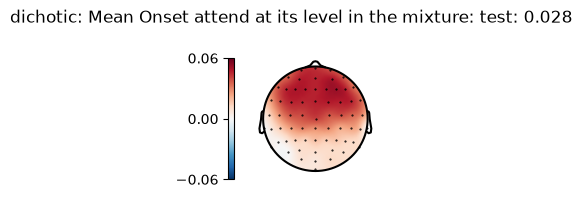

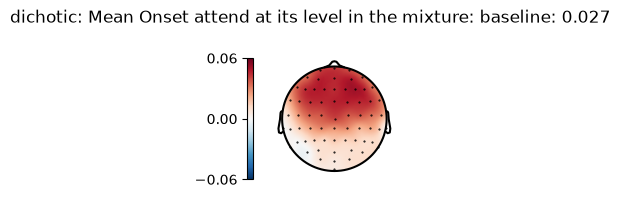

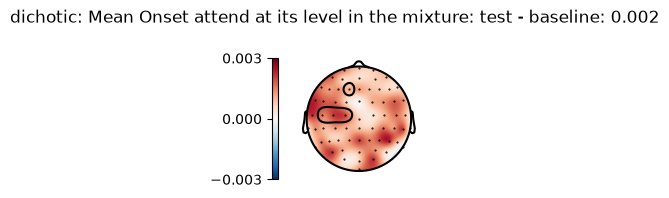

In [69]:
# Onset attend at its level in the mixture (dichotic)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_ATTEND_ONSET, 'dichotic')
show_topomap_trio(data, diff, result, 'Onset attend at its level in the mixture', 'dichotic', None)

In [70]:
display(result)
print(f"Onset attend at its level in the mixture (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend at its level in the mixture (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .041>

Onset attend at its level in the mixture (dichotic): TFCE t_max = 2.69, p = 0.041
Onset attend at its level in the mixture (dichotic): ROI model comparison t(12) = 2.432, p = 0.0158


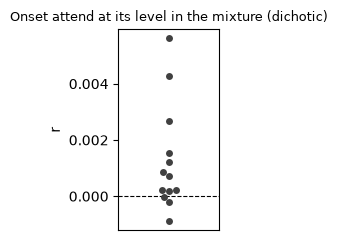

In [71]:
p = show_subject_swarm(diff, 'Onset attend at its level in the mixture', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


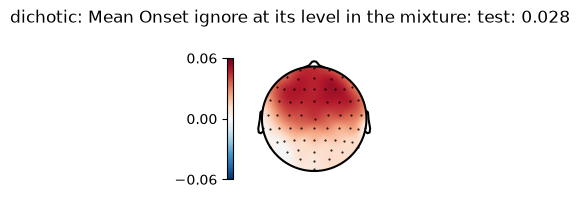

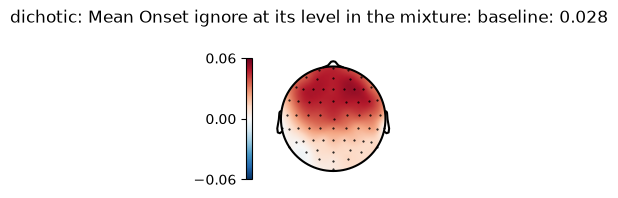

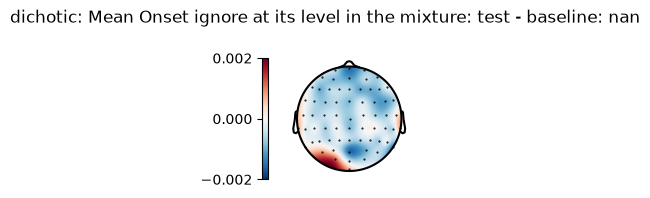

In [72]:
# Onset ignore at its level in the mixture (dichotic)
# reference: the same onsets unsplit, removed from FULL_INMIX
data, diff, result = compute_direct_comparison(FULL_INMIX, FULL_INMIX_NO_IGNORE_ONSET, 'dichotic')
show_topomap_trio(data, diff, result, 'Onset ignore at its level in the mixture', 'dichotic', None)

In [73]:
display(result)
print(f"Onset ignore at its level in the mixture (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore at its level in the mixture (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Onset ignore at its level in the mixture (dichotic): TFCE t_max = -0.21, p = 1.000
Onset ignore at its level in the mixture (dichotic): ROI model comparison t(12) = -2.165, p = 0.9744


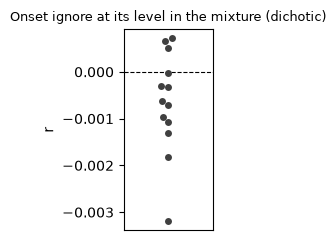

In [74]:
p = show_subject_swarm(diff, 'Onset ignore at its level in the mixture', 'dichotic')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


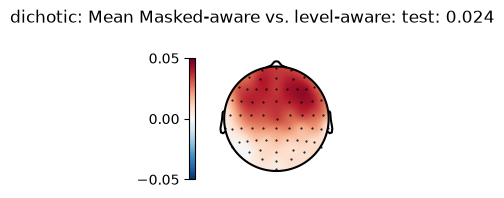

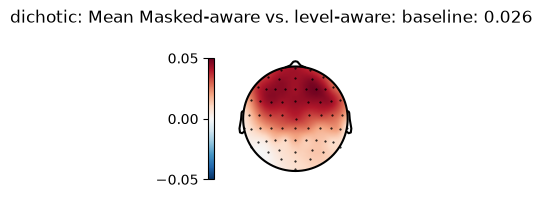

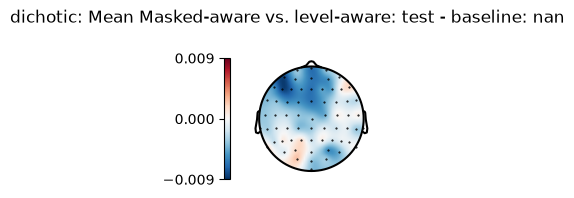

In [75]:
# Masked-aware vs. level-aware (dichotic)
# Brodbeck et al. 2020 ran this comparison too: the ignored-speaker-aware model still beat the loudness-only model, t = 9.21, p < .001 - the masking effect isn't just about volume.
data, diff, result = compute_direct_comparison(FULL_MASKED, LEVEL_AWARE, 'dichotic')
show_topomap_trio(data, diff, result, 'Masked-aware vs. level-aware', 'dichotic', None)

In [76]:
display(result)
print(f"Masked-aware vs. level-aware (dichotic): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Masked-aware vs. level-aware (dichotic): ROI model comparison t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = 1.000>

Masked-aware vs. level-aware (dichotic): TFCE t_max = 0.09, p = 1.000
Masked-aware vs. level-aware (dichotic): ROI model comparison t(12) = -1.202, p = 0.8737


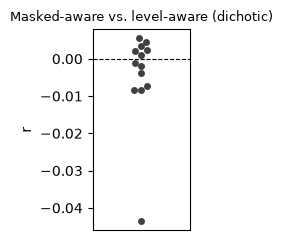

In [77]:
p = show_subject_swarm(diff, 'Masked-aware vs. level-aware', 'dichotic')